In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss, average_precision_score
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.calibration import CalibrationDisplay

In [2]:
analysis_sample = pd.read_parquet('../data/processed/analysis_sample.parquet')

X = analysis_sample.drop(['id', 'exam_weight', 'survey_psu', 'survey_strata', 'weight', 'height', 'undiagnosed_diabetes'], axis=1)
y = analysis_sample['undiagnosed_diabetes']

assert 'undiagnosed_diabetes' not in X.columns

features_a = X.columns.difference(['total_chol', 'hdl_chol']).to_list()
features_b = features_a + ['total_chol', 'hdl_chol']

num_cols = X.select_dtypes(include=['int', 'float']).columns.to_list()
bool_cols = X.select_dtypes(include='boolean').columns.to_list()
cat_cols = X.select_dtypes(include='category').columns.to_list()

X[bool_cols] = X[bool_cols].astype('float')
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

assert np.isclose(y_train.mean(), y_test.mean(), atol=0.005)
assert len(num_cols) + len(bool_cols) + len(cat_cols) ==  X.shape[1]

In [3]:
def make_preprocessor(features):
    num = [col for col in num_cols if col in features]
    bool_ = [col for col in bool_cols if col in features]
    cats = [col for col in cat_cols if col in features]
    num_pipeline = Pipeline([('med_imp', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
    bool_pipeline = Pipeline([('freq_imp', SimpleImputer(strategy='most_frequent'))])
    cat_pipeline = Pipeline([('cat_imp', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
    
    preprocessor = ColumnTransformer([
                                ('num', num_pipeline, num), 
                                ('bool', bool_pipeline, bool_),
                                ('cat', cat_pipeline, cats)
                                ])
    return preprocessor

In [4]:
model_a = Pipeline([('prep', make_preprocessor(features_a)), ('clf', LogisticRegression(max_iter=1000))])
model_b = Pipeline([('prep', make_preprocessor(features_b)), ('clf', LogisticRegression(max_iter=1000))])


model_a.fit(X_train[features_a], y_train)
model_b.fit(X_train[features_b], y_train)

a_pred = model_a.predict_proba(X_test[features_a])[:,1]
b_pred = model_b.predict_proba(X_test[features_b])[:,1]

roc_score_a = roc_auc_score(y_test, a_pred)
roc_score_b = roc_auc_score(y_test, b_pred)

pr_auc_a = average_precision_score(y_test, a_pred)
pr_auc_b = average_precision_score(y_test, b_pred)

brier_a = brier_score_loss(y_test, a_pred)
brier_b = brier_score_loss(y_test, b_pred)


results = pd.DataFrame({
    'ROC-AUC Score' : [roc_score_a, roc_score_b],
    'PR-AUC' : [pr_auc_a, pr_auc_b],
    'Brier' : [brier_a, brier_b]
}, index=['Model A', 'Model B'])

display(results)

,ROC-AUC Score,PR-AUC,Brier
Model A,0.816908,0.101301,0.033272
Model B,0.828377,0.141394,0.032351


In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

gb_a = Pipeline([('prep', make_preprocessor(features_a)), ('clf', HistGradientBoostingClassifier(random_state=42))])
gb_b = Pipeline([('prep', make_preprocessor(features_b)), ('clf', HistGradientBoostingClassifier(random_state=42))])

cv_results = {}
models = {
    'LogReg A': [model_a, features_a],
    'LogReg B': [model_b, features_b],
    'GBoost A' : [gb_a, features_a],
    'GBoost B' : [gb_b, features_b]
}

for name, values in models.items():
    model = values[0]
    feat = values[1]
    scores = cross_validate(model, X_train[feat], y_train, cv=cv, scoring=['roc_auc', 'average_precision'])
    cv_results[name] = {
        'ROC-AUC mean' : scores['test_roc_auc'].mean(),
        'ROC-AUC std' : scores['test_roc_auc'].std(),
        'PR-AUC mean' : scores['test_average_precision'].mean(),
        'PR-AUC std' : scores['test_average_precision'].std()
    }


cv_results_df = pd.DataFrame(cv_results).T
display(cv_results_df)

,ROC-AUC mean,ROC-AUC std,PR-AUC mean,PR-AUC std
LogReg A,0.758270,0.035503,0.096799,0.029052
LogReg B,0.796580,0.029320,0.119882,0.042697
GBoost A,0.745623,0.027968,0.105442,0.017293
GBoost B,0.761664,0.031674,0.126328,0.031849


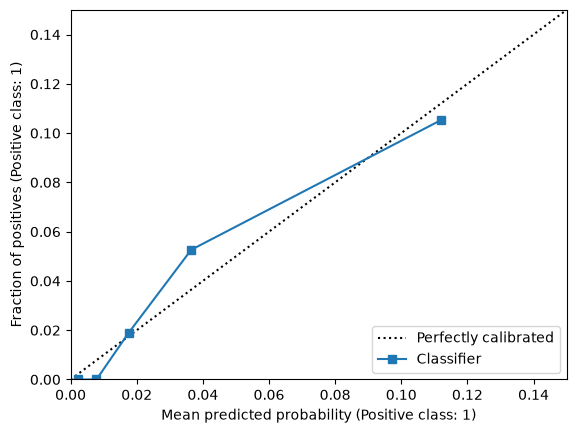

In [6]:
disp = CalibrationDisplay.from_predictions(y_test, b_pred, n_bins=5, strategy='quantile')
disp.ax_.set_xlim(0, 0.15)
disp.ax_.set_ylim(0, 0.15);

**Calibration (LogReg B, test set):** points lie close to the diagonal -> well calibrated.

Brier 0.0326 vs baseline 0.0344

Note: predictions only go up to ~0.12, and the test set has ~47 positives, so the evidence is limited.

In [7]:
X_test_sub = X_test.copy()
X_test_sub['age_group'] = pd.cut(X_test_sub['age_at_screening'], 
                                 bins=[20,40,60,np.inf], 
                                 labels=['20-39', '40-59', '60+'],
                                 right=False)
assert X_test_sub['age_group'].notna().all()


def subgroup_auc(col):
    subgroup_rows = []
    for group in X_test_sub[col].unique():
        mask = X_test_sub[col] == group
        if y_test[mask].nunique() < 2:
            continue
        roc_auc = roc_auc_score(y_test[mask], b_pred[mask])
        group_size = mask.sum()
        positives = y_test[mask].sum()
        subgroup_rows.append({'group': group, 'n' : group_size, 
                'positives': positives, 'ROC-AUC': roc_auc})

    return pd.DataFrame(subgroup_rows)

In [8]:
display(subgroup_auc('sex'))
display(subgroup_auc('age_group'))
display(subgroup_auc('race'))

,group,n,positives,ROC-AUC
0,female,723,23,0.860745
1,male,606,24,0.793743


,group,n,positives,ROC-AUC
0,60+,404,21,0.698371
1,40-59,431,22,0.834185
2,20-39,494,4,0.905102


,group,n,positives,ROC-AUC
0,other hispanic,121,7,0.807018
1,non-hispanic black,337,18,0.791188
2,mexican american,167,7,0.739286
3,non-hispanic white,472,7,0.861137
4,non-hispanic asian,162,6,0.819444
5,other/multi-racial,70,2,0.992647


In [9]:
coefs = model_b.named_steps['clf'].coef_[0]
feat_names = model_b.named_steps['prep'].get_feature_names_out()

feat_imp = pd.DataFrame({
    'coef': coefs,
    'names': feat_names,
    'odds_ratio' : np.exp(coefs)
}).sort_values(by='coef',key=abs, ascending=False)

display(feat_imp)

,coef,names,odds_ratio
7,-0.818552,num__hdl_chol,0.441070
0,0.696357,num__age_at_screening,2.006431
20,-0.512224,cat__race_non-hispanic white,0.599162
14,0.469285,bool__family_history_diabetes,1.598851
29,-0.464964,cat__years_in_us_< 5,0.628158
3,0.405691,num__waist_circ,1.500339
18,0.403001,cat__race_non-hispanic asian,1.496309
9,0.396749,bool__told_high_bp,1.486983
11,-0.391005,bool__told_high_chol,0.676377
19,0.387052,cat__race_non-hispanic black,1.472632


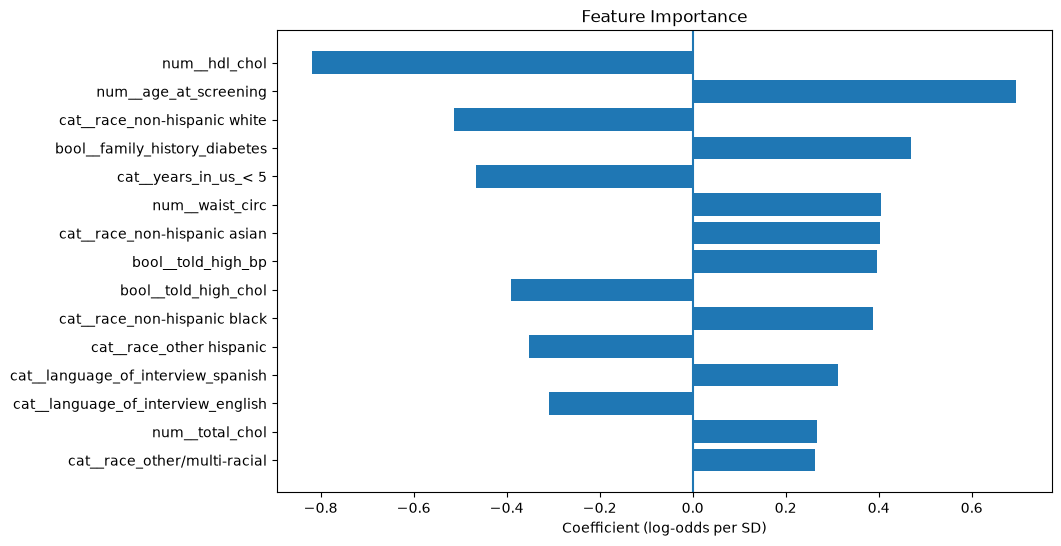

In [18]:
fig, ax = plt.subplots(figsize=(10,6))

ax.barh(y=feat_imp['names'].head(15), width=feat_imp['coef'].head(15))
ax.invert_yaxis()
ax.set_xlabel('Coefficient (log-odds per SD)')
ax.set_title('Feature Importance')
ax.axvline(0)

fig.savefig('../reports/figures/feature_importance.png', bbox_inches='tight')